# Population of Nonthaburi Province by District

**Data:** `data/raw/population.csv` — population by district for Buddhist Era 2562–2566 (2019–2023), yearly growth rate (%), and 2566 population density (people/km²). The `รวมยอด` row is the province total

**What it is used for:** the denominator for "waste per person" in other analyses, and to show that fast-growing districts will face more waste pressure

# ประชากรจังหวัดนนทบุรี รายอำเภอ

**ข้อมูล:** `data/raw/population.csv` — จำนวนประชากรรายอำเภอ พ.ศ. 2562–2566, อัตราการเพิ่ม (%) รายปี และความหนาแน่นประชากรปี 2566 (คน/ตร.กม.) มีแถว `รวมยอด` เป็นยอดรวมทั้งจังหวัด

**ใช้ทำอะไร:** เป็นตัวหารสำหรับคำนวณ "ขยะต่อหัว" ในการวิเคราะห์อื่น และอธิบายว่าอำเภอที่ประชากรโตเร็วจะมีแรงกดดันด้านขยะเพิ่มขึ้น

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/population.csv` (7 rows: total + 6 districts)

**โหลดข้อมูลดิบ** จาก `../data/raw/population.csv` (7 แถว: รวมยอด + 6 อำเภอ)

In [2]:
df = pd.read_csv('../data/raw/population.csv')
df

,อำเภอ,ประชากร_2562,ประชากร_2563,ประชากร_2564,ประชากร_2565,ประชากร_2566,อัตราเพิ่ม_2563,อัตราเพิ่ม_2564,อัตราเพิ่ม_2565,อัตราเพิ่ม_2566,ความหนาแน่นประชากร_2566,District_English
0,รวมยอด,1265387,1276745,1288637,1295916,1308092,0.89,0.93,0.56,0.94,2102.03,Total
1,อำเภอเมืองนนทบุรี,367189,365288,364074,361127,359949,-0.52,-0.33,-0.81,-0.33,4674.66,Mueang Nonthaburi District
2,อำเภอบางกรวย,141149,144586,147182,149652,152508,2.41,1.78,1.66,1.89,2656.93,Bang Kruai District
3,อำเภอบางใหญ่,156861,160270,163797,166606,170223,2.15,2.18,1.70,2.15,1765.80,Bang Yai District
4,อำเภอบางบัวทอง,281766,285698,288592,290954,294818,1.39,1.01,0.82,1.32,2532.80,Bang Bua Thong District
5,อำเภอไทรน้อย,69007,70806,72822,74611,76440,2.57,2.81,2.43,2.42,410.97,Sai Noi District
6,อำเภอปากเกร็ด,249415,250097,252170,252966,254154,0.27,0.83,0.32,0.47,2855.66,Pak Kret District


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

This dataset is already numeric and has no missing values

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

ข้อมูลชุดนี้เป็นตัวเลขอยู่แล้วและไม่มีค่าว่าง

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   อำเภอ                    7 non-null      object 
 1   ประชากร_2562             7 non-null      int64  
 2   ประชากร_2563             7 non-null      int64  
 3   ประชากร_2564             7 non-null      int64  
 4   ประชากร_2565             7 non-null      int64  
 5   ประชากร_2566             7 non-null      int64  
 6   อัตราเพิ่ม_2563          7 non-null      float64
 7   อัตราเพิ่ม_2564          7 non-null      float64
 8   อัตราเพิ่ม_2565          7 non-null      float64
 9   อัตราเพิ่ม_2566          7 non-null      float64
 10  ความหนาแน่นประชากร_2566  7 non-null      float64
 11  District_English         7 non-null      object 
dtypes: float64(5), int64(5), object(2)
memory usage: 800.0+ bytes


**Drop the `District_English` column**, which holds the English district names and is not used in the analysis

**ลบคอลัมน์ `District_English`** ซึ่งเป็นชื่ออำเภอภาษาอังกฤษ ไม่ได้ใช้ในการวิเคราะห์

In [4]:
df = df.drop('District_English', axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   อำเภอ                    7 non-null      object 
 1   ประชากร_2562             7 non-null      int64  
 2   ประชากร_2563             7 non-null      int64  
 3   ประชากร_2564             7 non-null      int64  
 4   ประชากร_2565             7 non-null      int64  
 5   ประชากร_2566             7 non-null      int64  
 6   อัตราเพิ่ม_2563          7 non-null      float64
 7   อัตราเพิ่ม_2564          7 non-null      float64
 8   อัตราเพิ่ม_2565          7 non-null      float64
 9   อัตราเพิ่ม_2566          7 non-null      float64
 10  ความหนาแน่นประชากร_2566  7 non-null      float64
dtypes: float64(5), int64(5), object(1)
memory usage: 744.0+ bytes


**Look at the first 5 rows** with `head()` to confirm the data is in the right format

**ดูตัวอย่าง 5 แถวแรก** ด้วย `head()` เพื่อยืนยันว่าข้อมูลอยู่ในรูปแบบที่ถูกต้อง

In [5]:
df.head()

,อำเภอ,ประชากร_2562,ประชากร_2563,ประชากร_2564,ประชากร_2565,ประชากร_2566,อัตราเพิ่ม_2563,อัตราเพิ่ม_2564,อัตราเพิ่ม_2565,อัตราเพิ่ม_2566,ความหนาแน่นประชากร_2566
0,รวมยอด,1265387,1276745,1288637,1295916,1308092,0.89,0.93,0.56,0.94,2102.03
1,อำเภอเมืองนนทบุรี,367189,365288,364074,361127,359949,-0.52,-0.33,-0.81,-0.33,4674.66
2,อำเภอบางกรวย,141149,144586,147182,149652,152508,2.41,1.78,1.66,1.89,2656.93
3,อำเภอบางใหญ่,156861,160270,163797,166606,170223,2.15,2.18,1.70,2.15,1765.80
4,อำเภอบางบัวทอง,281766,285698,288592,290954,294818,1.39,1.01,0.82,1.32,2532.80


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [6]:
df.to_csv('../data/clean/clean_population.csv')

**Import chart libraries** — `matplotlib` (basic charts) and `seaborn` (palettes/statistical charts)

**นำเข้าไลบรารีกราฟ** — `matplotlib` (วาดกราฟพื้นฐาน) และ `seaborn` (ชุดสี/กราฟสถิติ)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sbs

**Bar chart: population density by district, 2566 (2023)**
- Remove the `รวมยอด` (total) row to compare districts only, then sort from smallest to largest
- Put the value at the end of each bar

**What it shows:** Mueang Nonthaburi is the densest (urban area) and Sai Noi the least dense (agricultural area) — high density usually means more waste per area and more frequent collection

**กราฟแท่ง: ความหนาแน่นประชากรรายอำเภอ ปี 2566**
- ตัดแถว `รวมยอด` ออกเพื่อเทียบเฉพาะอำเภอ แล้วเรียงจากน้อยไปมาก
- ใส่ตัวเลขที่ปลายแท่ง

**สิ่งที่เห็น:** อำเภอเมืองนนทบุรีหนาแน่นที่สุด (เขตเมือง) ส่วนไทรน้อยหนาแน่นน้อยที่สุด (พื้นที่เกษตร) — ความหนาแน่นสูงมักหมายถึงขยะต่อพื้นที่สูงและต้องเก็บขนถี่ขึ้น

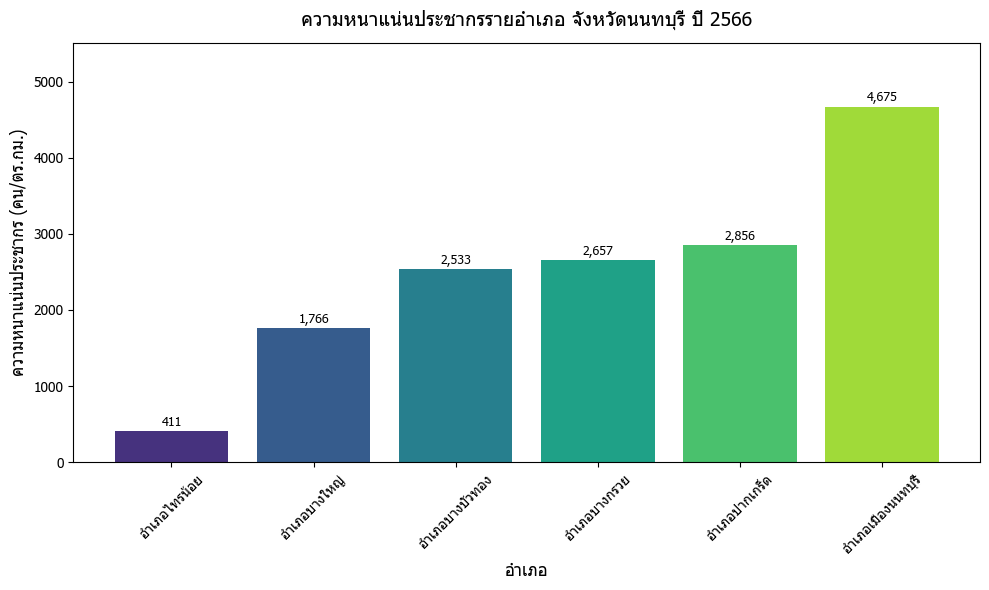

In [8]:
# Thai font setup (Windows has Tahoma, which supports Thai)
# ตั้งค่าฟอนต์ภาษาไทย (Windows มี Tahoma รองรับภาษาไทย)
plt.rcParams['font.family'] = 'Tahoma'
plt.rcParams['axes.unicode_minus'] = False

# Remove the "รวมยอด" (total) row to compare districts only
# ตัดแถว "รวมยอด" ออก เพื่อเปรียบเทียบเฉพาะรายอำเภอ
density = (
    df[df['อำเภอ'] != 'รวมยอด']
    .sort_values('ความหนาแน่นประชากร_2566', ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    density['อำเภอ'],
    density['ความหนาแน่นประชากร_2566'],
    color=sbs.color_palette('viridis', len(density)),
)

# Label the value at the end of each bar
# กำกับค่าที่ปลายแท่ง
for bar, value in zip(bars, density['ความหนาแน่นประชากร_2566']):
    ax.text(
        bar.get_x() + bar.get_width() / 2, value + 30,
        f'{value:,.0f}',
        ha='center', va='bottom', fontsize=9,
    )

ax.set_title('ความหนาแน่นประชากรรายอำเภอ จังหวัดนนทบุรี ปี 2566', fontsize=14, pad=12)
ax.set_ylabel('ความหนาแน่นประชากร (คน/ตร.กม.)', fontsize=12)
ax.set_xlabel('อำเภอ', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.margins(y=0.18)
plt.tight_layout()
plt.show()

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [9]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [10]:
# Prepare data: separate the total row and strip the word "อำเภอ" so names match the waste datasets
# เตรียมข้อมูล: แยกแถวรวมยอดออก และตัดคำว่า "อำเภอ" ให้ชื่อตรงกับชุดข้อมูลขยะ
years = [2562, 2563, 2564, 2565, 2566]
pop_cols = [f'ประชากร_{y}' for y in years]
rate_cols = [f'อัตราเพิ่ม_{y}' for y in years[1:]]
total = df[df['อำเภอ'] == 'รวมยอด'].iloc[0]
dist = df[df['อำเภอ'] != 'รวมยอด'].copy()
dist['อำเภอ'] = dist['อำเภอ'].str.replace('อำเภอ', '', n=1)
dist = dist.set_index('อำเภอ').reindex(DIST_ORDER)
dist[pop_cols]

,ประชากร_2562,ประชากร_2563,ประชากร_2564,ประชากร_2565,ประชากร_2566
อำเภอ,,,,,
เมืองนนทบุรี,367189,365288,364074,361127,359949
บางกรวย,141149,144586,147182,149652,152508
บางใหญ่,156861,160270,163797,166606,170223
บางบัวทอง,281766,285698,288592,290954,294818
ไทรน้อย,69007,70806,72822,74611,76440
ปากเกร็ด,249415,250097,252170,252966,254154


### 2.1 Line chart: total province population 2562–2566 (2019–2023)
**How to read it:** shows the direction of the province's population growth; the number on each point is that year's population

### 2.1 กราฟเส้น: ประชากรรวมทั้งจังหวัด 2562–2566
**วิธีอ่าน:** ดูทิศทางการเติบโตของประชากรทั้งจังหวัด ตัวเลขบนจุดคือจำนวนประชากรในปีนั้น

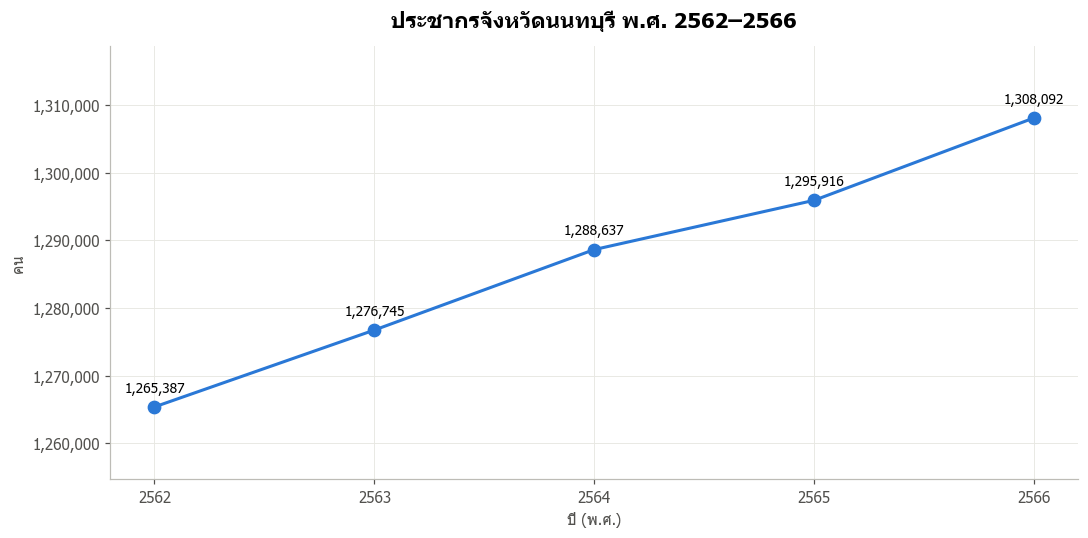

เพิ่มขึ้นรวม 42,705 คน (3.37%) ใน 4 ปี


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
vals = total[pop_cols].astype(float).values
ax.plot(years, vals, marker='o', markersize=8, linewidth=2, color=PALETTE[0])
for x, y in zip(years, vals):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_xticks(years); ax.yaxis.set_major_formatter(fmt_k)
ax.margins(y=0.25)
ax.set_title('ประชากรจังหวัดนนทบุรี พ.ศ. 2562–2566')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('คน')
plt.tight_layout(); plt.show()
print(f'เพิ่มขึ้นรวม {vals[-1] - vals[0]:,.0f} คน ({(vals[-1] / vals[0] - 1) * 100:.2f}%) ใน 4 ปี')

### 2.2 Multi-line chart: population by district 2562–2566
**How to read it:** each line is one district (district color) with its name at the end of the line — notice which lines rise steeply (fast growth) and which are flat/declining

### 2.2 กราฟเส้นหลายเส้น: ประชากรรายอำเภอ 2562–2566
**วิธีอ่าน:** แต่ละเส้นคือหนึ่งอำเภอ (สีประจำอำเภอ) มีชื่อกำกับที่ปลายเส้น — สังเกตว่าเส้นใดชันขึ้น (โตเร็ว) และเส้นใดแบน/ลดลง

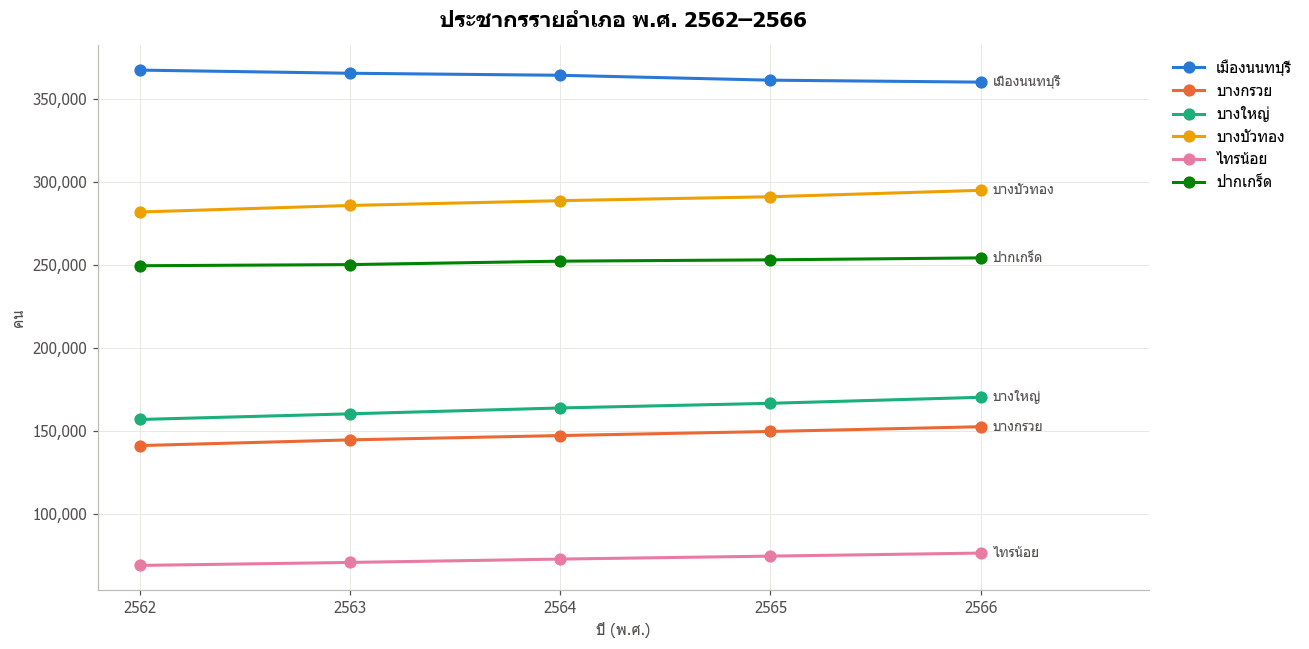

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
for d in dist.index:
    ax.plot(years, dist.loc[d, pop_cols], marker='o', markersize=7, linewidth=2, color=DIST_COLOR[d], label=d)
ax.set_xticks(years); ax.yaxis.set_major_formatter(fmt_k)
ax.set_xlim(years[0] - 0.2, years[-1] + 0.8)
end_labels(ax, years[-1], [(d, dist.loc[d, pop_cols[-1]]) for d in dist.index])
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ประชากรรายอำเภอ พ.ศ. 2562–2566')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('คน')
plt.tight_layout(); plt.show()

### 2.3 Pie chart: population share of each district, 2566 (2023)
**How to read it:** a big slice = a district with a large population, which is usually a main source of the province's waste

### 2.3 แผนภูมิวงกลม: สัดส่วนประชากรแต่ละอำเภอ ปี 2566
**วิธีอ่าน:** ชิ้นใหญ่ = อำเภอที่มีประชากรมาก ซึ่งมักเป็นแหล่งกำเนิดขยะหลักของจังหวัด

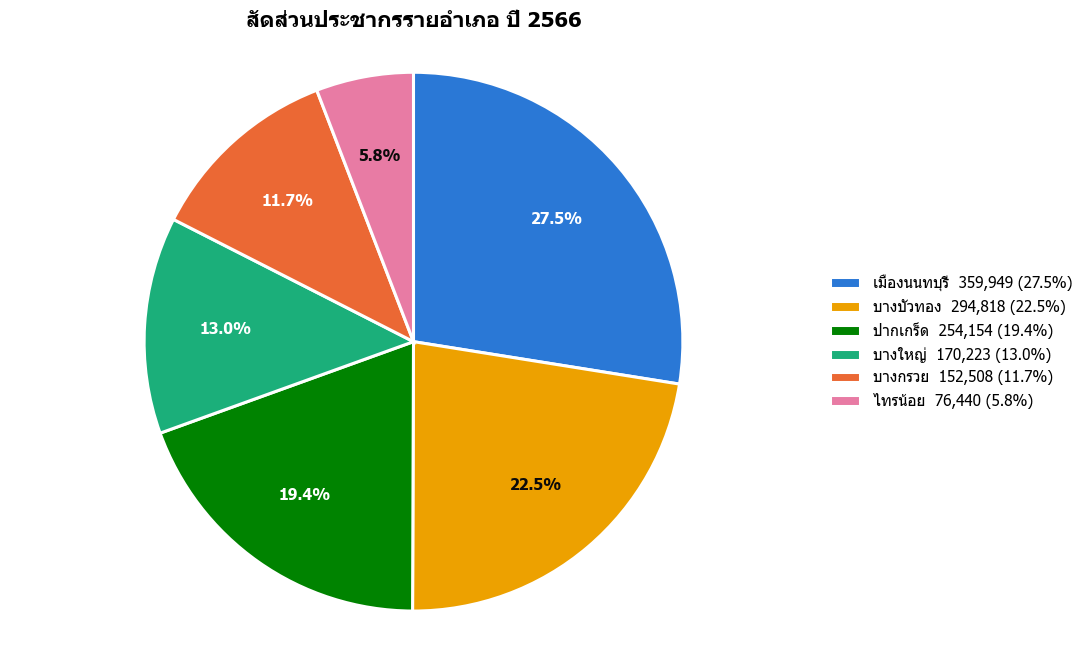

In [13]:
share = dist['ประชากร_2566'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, share.values, share.index, colors=[DIST_COLOR[d] for d in share.index],
          title='สัดส่วนประชากรรายอำเภอ ปี 2566')
plt.tight_layout(); plt.show()

### 2.4 Heatmap: population growth rate (%) by district × year
**What it does:** uses a **diverging** palette — orange = population growth, blue = population decline, light gray in the middle = 0%

**How to read it:** instantly shows which districts are steadily shrinking (e.g. the old urban core as people move to the suburbs) and which are growing fast

### 2.4 Heatmap: อัตราการเพิ่มประชากร (%) รายอำเภอ × ปี
**ทำอะไร:** ใช้ชุดสีแบบ **diverging** — สีส้ม = ประชากรเพิ่ม, สีน้ำเงิน = ประชากรลด, สีเทาอ่อนตรงกลาง = 0%

**วิธีอ่าน:** ช่วยเห็นทันทีว่าอำเภอใดประชากรลดลงต่อเนื่อง (เช่น เขตเมืองเดิมที่คนย้ายออกไปชานเมือง) และอำเภอใดโตเร็ว

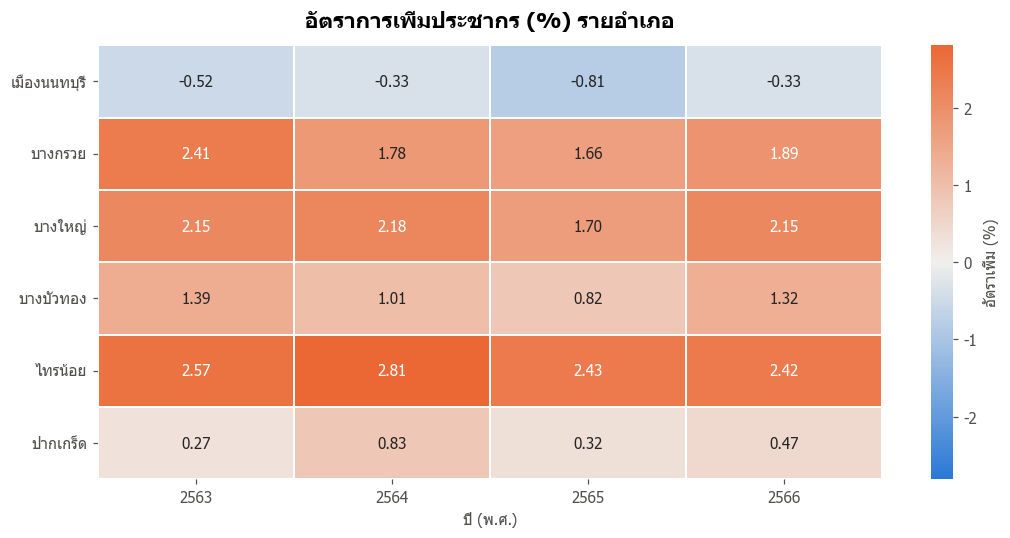

In [14]:
rates = dist[rate_cols].set_axis(years[1:], axis=1)
lim = np.abs(rates.values).max()
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(rates, annot=True, fmt='.2f', cmap=DIV_CMAP, norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim),
            linewidths=1, linecolor='white', cbar_kws={'label': 'อัตราเพิ่ม (%)'}, ax=ax)
ax.set_title('อัตราการเพิ่มประชากร (%) รายอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

### 2.5 Horizontal bar chart: cumulative population change 2562 → 2566 (%)
**How to read it:** bars to the right (orange) = growth, to the left (blue) = decline — fast-growing districts should plan for more waste in the future

### 2.5 กราฟแท่งแนวนอน: การเปลี่ยนแปลงประชากรสะสม 2562 → 2566 (%)
**วิธีอ่าน:** แท่งไปทางขวา (สีส้ม) = เพิ่มขึ้น, ไปทางซ้าย (สีน้ำเงิน) = ลดลง — อำเภอที่โตเร็วควรวางแผนรองรับปริมาณขยะที่จะเพิ่มขึ้นในอนาคต

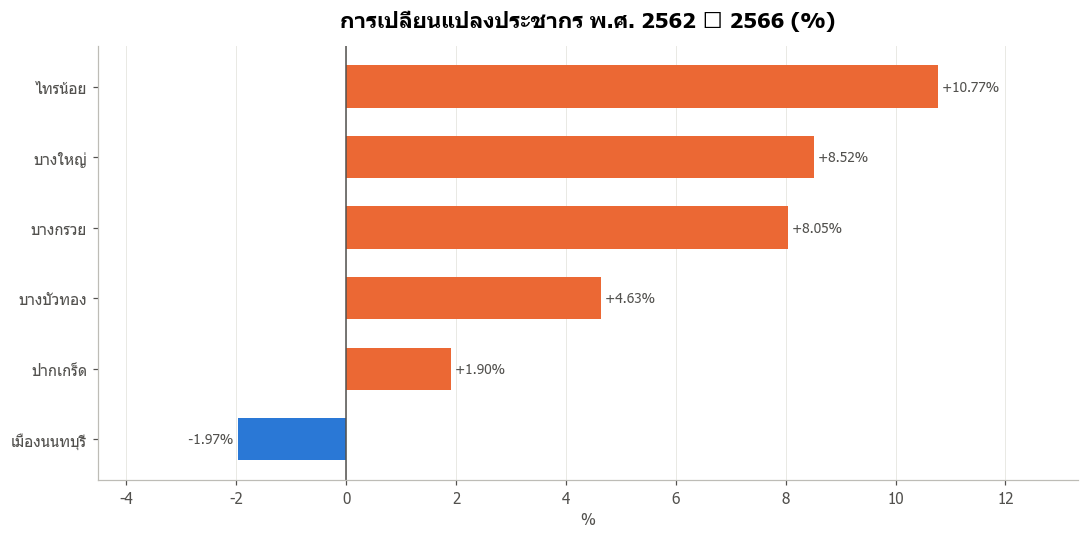

In [15]:
growth = ((dist['ประชากร_2566'] / dist['ประชากร_2562'] - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(growth.index, growth.values, height=0.6,
               color=[PALETTE[1] if v >= 0 else PALETTE[0] for v in growth.values])
for b, v in zip(bars, growth.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f' {v:+.2f}% ', va='center',
            ha='left' if v >= 0 else 'right', fontsize=9, color=TEXT)
ax.axvline(0, color=TEXT, linewidth=1)
ax.margins(x=0.2); ax.grid(axis='y', visible=False)
ax.set_title('การเปลี่ยนแปลงประชากร พ.ศ. 2562 → 2566 (%)'); ax.set_xlabel('%')
plt.tight_layout(); plt.show()

---
## Key Findings

1. **Nonthaburi's population is growing steadily**, from 1,265,387 (2562/2019) to 1,308,092 (2566/2023), or +3.4% in 4 years
2. **Mueang Nonthaburi is the only district whose population fell every year** (−0.3% to −0.8%/year), yet it still has the largest population (27.5%) and the highest density (~4,675 people/km²)
3. **Suburban districts grow fastest** — Sai Noi (~2.4–2.8%/year), Bang Yai and Bang Kruai (~1.7–2.4%/year), consistent with people moving from the city to the suburbs
4. **Implication for waste management:** fast-growing districts will generate more waste; plan ahead to expand collection trucks and sorting points

## สรุปข้อค้นพบ

1. **ประชากรนนทบุรีเพิ่มขึ้นต่อเนื่อง** จาก 1,265,387 คน (2562) เป็น 1,308,092 คน (2566) หรือ +3.4% ใน 4 ปี
2. **อำเภอเมืองนนทบุรีเป็นอำเภอเดียวที่ประชากรลดลงทุกปี** (−0.3% ถึง −0.8%/ปี) แต่ยังมีประชากรมากที่สุด (27.5%) และหนาแน่นที่สุด (~4,675 คน/ตร.กม.)
3. **อำเภอชานเมืองโตเร็วที่สุด** — ไทรน้อย (~2.4–2.8%/ปี), บางใหญ่ และบางกรวย (~1.7–2.4%/ปี) สอดคล้องกับการย้ายออกจากเขตเมืองไปชานเมือง
4. **นัยต่อการจัดการขยะ:** อำเภอที่ประชากรโตเร็วจะมีปริมาณขยะเพิ่มขึ้นตาม ควรวางแผนขยายรถเก็บขนและจุดคัดแยกล่วงหน้า